# 04 – Where is the charging gap?

**Business question 2.** Which provinces have the least public charging for their cars?

**Two important choices**

1. **All cars, not electric cars, are used for the province comparison.** Open data has no electric car count by province (TÜİK publishes fuel type only for Türkiye as a whole; a freedom of information request is pending). The province measure is therefore **public charging stations per 10,000 cars**. It shows how ready each province is for the electric cars that will come, not how well today's electric cars are served. If province EV data arrives, this notebook will be updated.
2. **Stations, not sockets, in provinces.** The EPDK station list has no socket count: a station can have 2 sockets or 20. Sockets (AC and DC) are only available nationally, from the EPDK monthly report. The national trend uses sockets; the province comparison uses stations. The two are never mixed.

**Caveat: home charging.** Households living in a building with a car park can more often charge at home. This is used in question 4 (`no_parking_share_2021`), not here.

In [1]:
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PROCESSED = "../data/processed/"
FIGURES = "../outputs/figures/"

# Chart style: light surface, quiet grid and axes, 2px lines
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": TEXT, "axes.labelcolor": TEXT_2,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
})


def add_source(fig, text):
    fig.text(0.01, 0.01, text, fontsize=8, color=TEXT_2)

## 1. National trend: is charging keeping pace?

Electric cars on the road (TÜİK, end of month) per public charging socket (EPDK, end of month), September 2025 – September 2026. EPDK's monthly report gives the socket split only from September 2025.

If the line rises, electric cars are growing faster than public charging.

In [2]:
national = pd.read_csv(PROCESSED + "national_monthly.csv")
national["date"] = pd.PeriodIndex(national["month"], freq="M").start_time
sockets = national.dropna(subset=["sockets_total"]).set_index("month")

# Electric cars (TÜİK) are used, as in notebook 03; EPDK's stock also counts other electric vehicles
sockets["ev_per_socket"] = sockets["cars_electric"] / sockets["sockets_total"]
sockets["ev_per_dc_socket"] = sockets["cars_electric"] / sockets["sockets_dc"]
sockets["dc_share"] = sockets["sockets_dc"] / sockets["sockets_total"] * 100
sockets[["cars_electric", "sockets_ac", "sockets_dc", "sockets_total",
         "ev_per_socket", "ev_per_dc_socket", "dc_share"]].round(1)

,cars_electric,sockets_ac,sockets_dc,sockets_total,ev_per_socket,ev_per_dc_socket,dc_share
month,,,,,,,
2025-09,319155.0,19992.0,15010.0,35002.0,9.1,21.3,42.9
2025-10,332010.0,20677.0,15603.0,36280.0,9.2,21.3,43.0
2025-11,348908.0,21422.0,16051.0,37473.0,9.3,21.7,42.8
2025-12,370591.0,22095.0,16713.0,38808.0,9.5,22.2,43.1
2026-01,385876.0,22635.0,17059.0,39694.0,9.7,22.6,43.0
2026-02,395697.0,23142.0,17433.0,40575.0,9.8,22.7,43.0
2026-03,408314.0,23900.0,18038.0,41938.0,9.7,22.6,43.0
2026-04,423793.0,24468.0,18541.0,43009.0,9.9,22.9,43.1
2026-05,436474.0,25125.0,19050.0,44175.0,9.9,22.9,43.1


In [3]:
first, last = sockets.iloc[0], sockets.iloc[-1]
growth = pd.DataFrame({
    "Sep 2025": first[["cars_electric", "sockets_ac", "sockets_dc", "sockets_total"]],
    "Sep 2026": last[["cars_electric", "sockets_ac", "sockets_dc", "sockets_total"]],
})
growth["growth_%"] = (growth["Sep 2026"] / growth["Sep 2025"] - 1) * 100
growth.round(1)

,Sep 2025,Sep 2026,growth_%
cars_electric,319155.0,486359.0,52.389591
sockets_ac,19992.0,27664.0,38.37535
sockets_dc,15010.0,21307.0,41.952032
sockets_total,35002.0,48971.0,39.909148


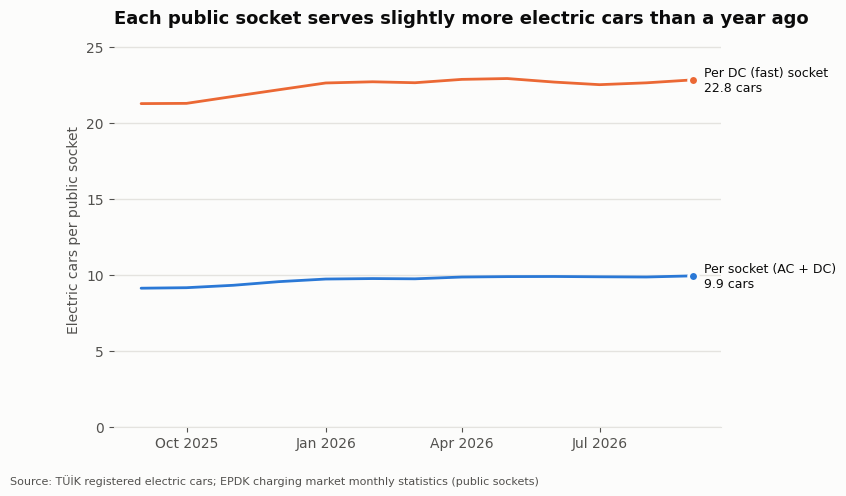

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.2))
series = {"ev_per_dc_socket": ("Per DC (fast) socket", ORANGE), "ev_per_socket": ("Per socket (AC + DC)", BLUE)}
for col, (label, color) in series.items():
    ax.plot(sockets["date"], sockets[col], color=color)
    ax.plot(sockets["date"].iloc[-1], sockets[col].iloc[-1], "o", color=color, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{label}\n{sockets[col].iloc[-1]:.1f} cars", (sockets["date"].iloc[-1], sockets[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT)

ax.set_title("Each public socket serves slightly more electric cars than a year ago")
ax.set_ylabel("Electric cars per public socket")
ax.set_ylim(0, 26)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.subplots_adjust(right=0.8, bottom=0.12)
add_source(fig, "Source: TÜİK registered electric cars; EPDK charging market monthly statistics (public sockets)")
fig.savefig(FIGURES + "04_ev_per_socket_national.png", dpi=200)
plt.show()

**How to read this chart:** each point is the number of electric cars on the road for every public charging socket in Türkiye. The blue line counts all sockets, the orange line only DC (fast) sockets.

**What it shows**
- **Charging is growing fast, but electric cars are growing faster.** In one year, electric cars grew 52% and public sockets 40% (AC 38%, DC 42%). As a result, each socket now serves **9.9 electric cars, up from 9.1** a year ago.
- **DC sockets are keeping pace slightly better than AC:** their share rose from 42.9% to 43.5% of all sockets. Per DC socket there are 22.8 electric cars (21.3 a year ago).
- The ratio rose quickly at the end of 2025, when electric car registrations peaked (December), and has been **almost flat since February 2026** (9.7–9.9). The sector added about 1,100 sockets a month in 2026.

**Comparison with the UK:** the UK has about 21 battery electric cars per public charging *device* (2026). Türkiye's 9.9 is per *socket*, and a device often has two or more sockets, so the figures are not directly comparable. Even allowing for this, Türkiye's public network is not small for today's number of electric cars. The issue is that the fleet is growing by 15,000–20,000 electric cars a month.

## 2. Province table, September 2026

One row per province: public charging stations (EPDK list, 30 October 2026), cars (TÜİK, September 2026) and population (ADNKS 2025). Two measures:

- **Stations per 10,000 cars**: the main measure (readiness for future electric cars).
- **Stations per 100,000 people**: a check. It does not depend on where cars are registered (see the Istanbul and Ankara note below).

Unlike the UK project, a **higher** value means **more** charging, so the gap is at the **bottom** of the ranking.

The 19 mobile charging vans and 5 stations with an unknown province (notebook 02) are not counted, so the 81 provinces have 12,736 of the 12,760 public stations.

In [5]:
provinces = pd.read_csv(PROCESSED + "province_analysis_table.csv")
provinces["cars_per_1000_people"] = provinces["cars"] / provinces["population_2025"] * 1000
provinces["stations_per_10k_cars"] = provinces["public_stations"] / provinces["cars"] * 10_000
provinces["stations_per_100k_people"] = provinces["public_stations"] / provinces["population_2025"] * 100_000
# Rank 1 = least public charging for its cars (the biggest gap)
provinces["gap_rank"] = provinces["stations_per_10k_cars"].rank(method="min").astype(int)

turkiye = provinces[["public_stations", "cars", "population_2025"]].sum()
TR_PER_10K_CARS = turkiye["public_stations"] / turkiye["cars"] * 10_000
TR_PER_100K_PEOPLE = turkiye["public_stations"] / turkiye["population_2025"] * 100_000
MEDIAN_PER_10K_CARS = provinces["stations_per_10k_cars"].median()

print(f"Türkiye: {TR_PER_10K_CARS:.1f} stations per 10,000 cars, {TR_PER_100K_PEOPLE:.1f} per 100,000 people")
print(f"Median province: {MEDIAN_PER_10K_CARS:.1f} per 10,000 cars, "
      f"{provinces['stations_per_100k_people'].median():.1f} per 100,000 people")
provinces["stations_per_10k_cars"].describe().round(1)

Türkiye: 7.0 stations per 10,000 cars, 14.8 per 100,000 people
Median province: 7.9 per 10,000 cars, 12.6 per 100,000 people


count    81.0
mean      9.1
std       4.5
min       2.4
25%       5.8
50%       7.9
75%      11.9
max      28.3
Name: stations_per_10k_cars, dtype: float64

In [6]:
big_three = provinces[provinces["province"].isin(["İstanbul", "Ankara", "İzmir"])]
big_three[["province", "cars", "public_stations", "cars_per_1000_people",
           "stations_per_10k_cars", "stations_per_100k_people", "gap_rank"]].round(1)

,province,cars,public_stations,cars_per_1000_people,stations_per_10k_cars,stations_per_100k_people,gap_rank
0,İstanbul,4210192,2742,267.2,6.5,17.4,31
6,İzmir,1130163,565,250.9,5.0,12.5,11
22,Ankara,2271129,1287,384.3,5.7,21.8,20


Türkiye as a whole has **7.0 public stations per 10,000 cars**; the typical (median) province has 7.9. The three largest cities are all **below** the national figure per car. Istanbul and Ankara are **above** it per person, because they have many more cars per person (Ankara 384 per 1,000 people, Istanbul 267, Türkiye 210). **İzmir is below on both measures** (5.0 per 10,000 cars, 12.5 per 100,000 people), so its gap is real.

Ankara's very high car ownership is partly a registration effect: public bodies and companies register cars at their head office. So for Ankara and Istanbul, the per-car measure probably makes the gap look somewhat bigger than it is.

## 3. By region (12 İBBS-1 regions)

In [7]:
regions = (provinces.groupby(["region_code", "region"], as_index=False)
           [["public_stations", "cars", "population_2025"]].sum())
regions["stations_per_10k_cars"] = regions["public_stations"] / regions["cars"] * 10_000
regions["stations_per_100k_people"] = regions["public_stations"] / regions["population_2025"] * 100_000
regions["cars_per_1000_people"] = regions["cars"] / regions["population_2025"] * 1000
regions = regions.sort_values("stations_per_10k_cars").reset_index(drop=True)
regions.round(1)

,region_code,region,public_stations,cars,population_2025,stations_per_10k_cars,stations_per_100k_people,cars_per_1000_people
0,TR5,Batı Anadolu,1608,2809480,8516084,5.7,18.9,329.9
1,TR6,Akdeniz,1511,2455177,11028175,6.2,13.7,222.6
2,TR8,Batı Karadeniz,589,930636,4716187,6.3,12.5,197.3
3,TR1,İstanbul,2742,4210192,15754053,6.5,17.4,267.2
4,TR3,Ege,1832,2581295,11011261,7.1,16.6,234.4
5,TRC,Güneydoğu Anadolu,553,725668,9587992,7.6,5.8,75.7
6,TR4,Doğu Marmara,1513,1822019,8759256,8.3,17.3,208.0
7,TRA,Kuzeydoğu Anadolu,150,173288,2115281,8.7,7.1,81.9
8,TR9,Doğu Karadeniz,382,436094,2699769,8.8,14.1,161.5
9,TR7,Orta Anadolu,748,844201,4164985,8.9,18.0,202.7


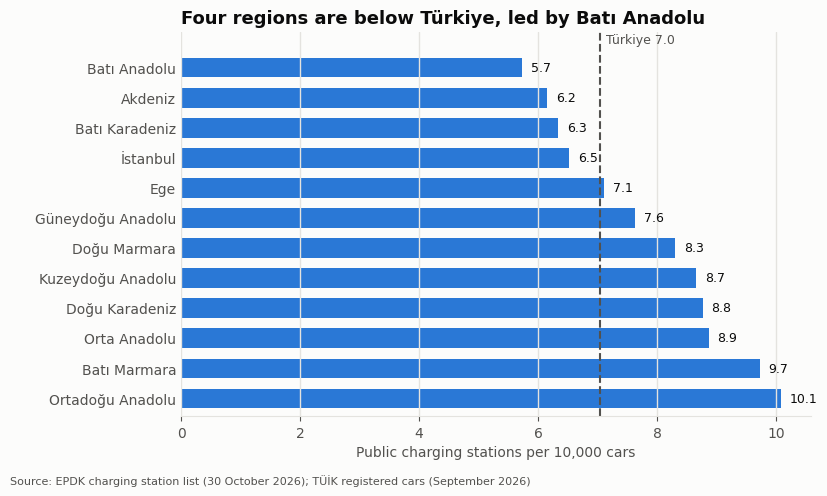

In [8]:
plot = regions.sort_values("stations_per_10k_cars", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(plot["region"], plot["stations_per_10k_cars"], color=BLUE, height=0.65)
for y, value in enumerate(plot["stations_per_10k_cars"]):
    ax.text(value + 0.15, y, f"{value:.1f}", va="center", fontsize=9, color=TEXT)
ax.axvline(TR_PER_10K_CARS, color=TEXT_2, linewidth=1.5, linestyle="--")
ax.text(TR_PER_10K_CARS + 0.1, len(plot) - 0.2, f"Türkiye {TR_PER_10K_CARS:.1f}", ha="left", fontsize=9, color=TEXT_2)
ax.set_ylim(-0.6, len(plot) + 0.2)

ax.set_title("Four regions are below Türkiye, led by Batı Anadolu")
ax.set_xlabel("Public charging stations per 10,000 cars")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", length=0)
plt.subplots_adjust(left=0.2, bottom=0.14)
add_source(fig, "Source: EPDK charging station list (30 October 2026); TÜİK registered cars (September 2026)")
fig.savefig(FIGURES + "05_stations_per_car_by_region.png", dpi=200)
plt.show()

**How to read this chart:** each bar is the number of public charging stations for every 10,000 registered cars in the region. A **shorter** bar means **less** charging for its cars, i.e. a bigger gap. The dashed line is Türkiye.

**What it shows**
- **The biggest gaps are in the regions with the most cars:** Batı Anadolu (Ankara, Konya, Karaman; 5.7), Akdeniz (6.2), Batı Karadeniz (6.3) and Istanbul (6.5). Batı Anadolu's low figure is driven by Ankara, which is partly a registration effect (see above).
- **The highest values are in eastern regions** (Ortadoğu Anadolu 10.1, Kuzeydoğu Anadolu 8.7) and Batı Marmara (9.7). In the east this is mainly because there are **few cars** (76–87 per 1,000 people, against 210 nationally), not because there are many stations: per person, these regions have the **least** charging in Türkiye (Güneydoğu Anadolu 5.8 per 100,000 people, against 14.8 nationally). Many of their stations are probably on main roads and serve through traffic.
- Batı Marmara (Tekirdağ, Edirne, Kırklareli, Balıkesir, Çanakkale) is high on **both** measures, probably because it sits on the main routes from Istanbul to Europe and to the Aegean coast.

## 4. Provinces with the biggest gaps

In [9]:
lowest = provinces.nsmallest(15, "stations_per_10k_cars")
lowest[["gap_rank", "province", "region", "cars", "public_stations",
        "stations_per_10k_cars", "stations_per_100k_people", "cars_per_1000_people"]].round(1)

,gap_rank,province,region,cars,public_stations,stations_per_10k_cars,stations_per_100k_people,cars_per_1000_people
30,1,Hatay,Akdeniz,290403,71,2.4,4.5,184.1
32,2,Osmaniye,Akdeniz,116717,33,2.8,5.8,206.9
73,3,Gaziantep,Güneydoğu Anadolu,335306,118,3.5,5.3,150.9
72,4,Adıyaman,Güneydoğu Anadolu,73551,27,3.7,4.4,119.0
13,5,Uşak,Ege,89140,35,3.9,9.3,238.1
43,6,Zonguldak,Batı Karadeniz,120545,51,4.2,8.7,206.0
28,7,Adana,Akdeniz,469863,202,4.3,8.8,205.8
31,8,Kahramanmaraş,Akdeniz,202485,88,4.3,7.7,176.6
74,9,Kilis,Güneydoğu Anadolu,14582,7,4.8,4.4,92.7
35,10,Kırşehir,Orta Anadolu,50176,25,5.0,10.3,206.7


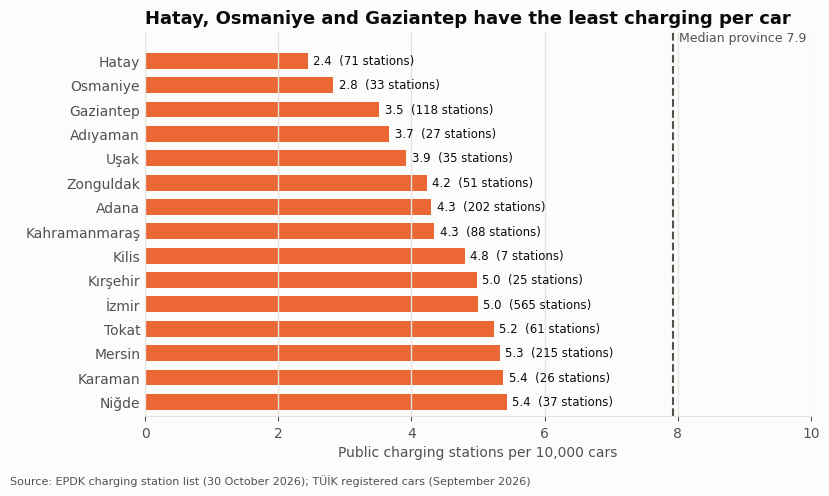

In [10]:
plot = lowest.sort_values("stations_per_10k_cars", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(plot["province"], plot["stations_per_10k_cars"], color=ORANGE, height=0.65)
for y, (value, stations) in enumerate(zip(plot["stations_per_10k_cars"], plot["public_stations"])):
    ax.text(value + 0.08, y, f"{value:.1f}  ({stations} stations)", va="center", fontsize=8.5, color=TEXT)
ax.axvline(MEDIAN_PER_10K_CARS, color=TEXT_2, linewidth=1.5, linestyle="--")
ax.text(MEDIAN_PER_10K_CARS + 0.1, len(plot) - 0.2, f"Median province {MEDIAN_PER_10K_CARS:.1f}",
        ha="left", fontsize=9, color=TEXT_2)
ax.set_ylim(-0.6, len(plot) + 0.2)

ax.set_title("Hatay, Osmaniye and Gaziantep have the least charging per car")
ax.set_xlabel("Public charging stations per 10,000 cars")
ax.set_xlim(0, 10)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.tick_params(axis="y", length=0)
plt.subplots_adjust(left=0.16, bottom=0.14)
add_source(fig, "Source: EPDK charging station list (30 October 2026); TÜİK registered cars (September 2026)")
fig.savefig(FIGURES + "06_lowest_15_provinces.png", dpi=200)
plt.show()

In [11]:
# Check: are the lowest 15 also low per person? (so the result does not depend on where cars are registered)
median_per_person = provinces["stations_per_100k_people"].median()
# Spearman correlation = correlation of the ranks
ranks = provinces[["stations_per_10k_cars", "stations_per_100k_people", "cars_per_1000_people"]].rank()
print("Lowest 15 below the median per person:", (lowest["stations_per_100k_people"] < median_per_person).sum(), "of 15")
print("Spearman correlation of the two measures, all 81 provinces:",
      round(ranks["stations_per_10k_cars"].corr(ranks["stations_per_100k_people"]), 2))
print("Spearman correlation of stations per car with cars per person:",
      round(ranks["stations_per_10k_cars"].corr(ranks["cars_per_1000_people"]), 2))

Lowest 15 below the median per person: 15 of 15
Spearman correlation of the two measures, all 81 provinces: 0.22
Spearman correlation of stations per car with cars per person: -0.39


In [12]:
highest = provinces.nlargest(10, "stations_per_10k_cars")
highest[["province", "region", "cars", "public_stations",
         "stations_per_10k_cars", "stations_per_100k_people", "cars_per_1000_people"]].round(1)

,province,region,cars,public_stations,stations_per_10k_cars,stations_per_100k_people,cars_per_1000_people
69,Hakkari,Ortadoğu Anadolu,3532,10,28.3,3.6,12.6
75,Diyarbakır,Güneydoğu Anadolu,95349,198,20.8,10.7,51.5
80,Şırnak,Güneydoğu Anadolu,9556,18,18.8,3.1,16.7
67,Tunceli,Ortadoğu Anadolu,6075,10,16.5,11.8,71.4
68,Bitlis,Ortadoğu Anadolu,12775,21,16.4,5.8,35.4
78,Mardin,Güneydoğu Anadolu,39601,62,15.7,6.9,43.8
36,Nevşehir,Orta Anadolu,76267,117,15.3,36.5,238.2
61,Ardahan,Kuzeydoğu Anadolu,5240,8,15.3,8.9,58.0
70,Muş,Ortadoğu Anadolu,14276,21,14.7,5.4,36.7
77,Batman,Güneydoğu Anadolu,25952,36,13.9,5.4,39.2


**How to read this chart:** the same measure as the regional chart, for the 15 provinces with the lowest values. The number of public stations is in brackets. The dashed line is the median of all 81 provinces.

**What it shows**
- **Hatay (2.4), Osmaniye (2.8) and Gaziantep (3.5) have the least charging for their cars**, between a third and a half of the typical province (7.9). Hatay has 290,000 cars and 71 public stations.
- **Seven of the lowest nine provinces (Hatay, Osmaniye, Gaziantep, Adıyaman, Adana, Kahramanmaraş and Kilis) are in the area hit by the February 2023 earthquakes.** This is a likely explanation (rebuilding came first, and charging networks expanded mostly after 2023), but it is not tested here.
- **Large cities are also in the list:** Adana (202 stations for 470,000 cars), İzmir (565 for 1.13 million) and Mersin (215 for 403,000). In absolute terms these are the biggest gaps: İzmir would need about 330 more stations just to reach the median province.
- **The result is robust:** all 15 provinces are also below the median *per person*, so the list does not depend on where cars are registered.

**The top of the ranking needs care.** The highest values are in eastern provinces with very few cars (Hakkari 28.3, Diyarbakır 20.8, Şırnak 18.8; 13–52 cars per 1,000 people). Ten stations in Hakkari serve 3,500 cars. Across all 81 provinces, provinces with fewer cars per person have *more* stations per car (Spearman −0.39), and the two measures agree only weakly (Spearman 0.22). So "stations per car" is a good way to find the gaps in provinces with many cars, but a high value in a province with few cars mostly reflects stations on through routes. Nevşehir (Cappadocia, 15.3 per 10,000 cars and 36.5 per 100,000 people) is the clear tourism case.

**Data caveat:** the EPDK list was read page by page and 16,613 of the 17,113 stations the page reports were found (notebook 02). If the missing 3% is spread unevenly, some provinces may be slightly undercounted.

In [13]:
# Stations needed to bring each of the lowest 15 up to the median province (at today's car numbers)
lowest = lowest.assign(stations_to_median=(MEDIAN_PER_10K_CARS * lowest["cars"] / 10_000 - lowest["public_stations"]).round())
lowest[["province", "public_stations", "stations_to_median"]].sort_values("stations_to_median", ascending=False)

,province,public_stations,stations_to_median
6,İzmir,565,330.0
28,Adana,202,170.0
30,Hatay,71,159.0
73,Gaziantep,118,148.0
29,Mersin,215,105.0
31,Kahramanmaraş,88,72.0
32,Osmaniye,33,59.0
43,Zonguldak,51,44.0
13,Uşak,35,36.0
72,Adıyaman,27,31.0


In [14]:
provinces.to_csv(PROCESSED + "province_charging_gap.csv", index=False)
print(provinces.shape)

(81, 25)


## Answer to question 2

- **Nationally, public charging is growing fast but electric cars are growing faster.** Sockets grew 40% in a year, electric cars 52%, so each socket serves 9.9 electric cars (9.1 a year ago). The ratio has been flat since February 2026, so the network is roughly keeping pace at about 1,100 new sockets a month.
- **By region, the biggest gaps are where most cars are:** Batı Anadolu, Akdeniz, Batı Karadeniz and Istanbul, all below Türkiye's 7.0 stations per 10,000 cars.
- **By province, the biggest gaps are in the south (Hatay, Osmaniye, Gaziantep, Adıyaman, Adana, Kahramanmaraş) and in large cities such as İzmir, Adana and Mersin.** These provinces are low on both measures (per car and per person). İzmir, Adana, Gaziantep, Mersin and Hatay together would need about 900 more stations to reach the median province, at today's car numbers.
- **Eastern provinces look well served per car only because they have few cars.** They are not a priority for city charging, but they matter for charging along main roads.

These provinces are candidates for investment. Question 4 combines this measure with income, car ownership and home parking before recommending where to invest.